In [1]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import fractional_matrix_power
from numpy import array, diag, dot, maximum, empty, repeat, ones, sum
from numpy.linalg import inv
import scipy as sp
import scipy.stats as sps
import scipy.io as spio
import astra
from venv import create
import pylops
from scipy import sparse
from scipy.ndimage import convolve
import scipy.special as spe
import requests
import h5py
from trips.utilities.io import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *


import sys
sys.path.append("../")


from voxelgrad import VoxelDynamicTomoOperator

import jlinops

from msolver import VanillaGKS
from msolver import MMGKS
from msolver import IASGKS

from voxelgrad import build_spatiotemporal_neumann2d

from voxelgrad import CGWeightedVoxelGradPinvGPUOperator


from PIL import Image


/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Set up problem

In [2]:
N_ITER = 25

In [3]:
(F, d, Aseq, B, nx, ny, nt) = generate_emoji(dataset = 30)

data already downloaded.


In [4]:
which_times = np.arange(0, 3)
how_many = len(which_times)
print(which_times)

[0 1 2]


In [5]:
which_times

array([0, 1, 2])

In [6]:
# which_times = [2*(1 -1), 2*(4 -1), 2*(8 -1), 2*(11 -1), 2*(16 -1)]
# loading_which_labels = ["01", "04", "08", "11", "15"]
# how_many = len(which_times)
# # Load all images
# photos = []
# for label in loading_which_labels:
#     image_path = f"frame{label}c.jpg"
#     image = Image.open(image_path)
#     image_array = np.array(image)
#     photos.append(image_array)

In [7]:
voxel_shape = (nx, ny, how_many)
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
b = np.hstack([ B[j] for j in which_times ] ) 
L = build_spatiotemporal_neumann2d(voxel_shape)
#NOISE_VAR = 0.0001
NOISE_VAR = 0.1*0.4

np.random.seed(0)
#b_noisy = b + np.sqrt(NOISE_VAR)*np.random.normal(size=len(b))
b_noisy = b.copy()

In [8]:
A.shape

(6510, 49152)

In [9]:
b.shape

(6510,)

# Individual L2 reconstructions?

In [10]:
vgks_recons = []
for j in range(how_many):
    A = Aseq[which_times[j]]
    btrunc = B[which_times[j]]
    L = jlinops.Neumann2D((nx, ny))

    v_gks_solver = VanillaGKS(A, L, btrunc, noise_var=NOISE_VAR)
    vdata = v_gks_solver.solve(n_iter=N_ITER, init_dim=5)
    vgks_recons.append(vdata)

20008.702460316348
29709.67224755189
32206.22749006488
32864.62989977501


32088.504347183592
31365.647146141113
30723.59255798709
30372.32097404902
30155.26425544072
30006.52257549673
29944.10295626849
29933.488748688957
29986.883113383185
30075.76653834323
30192.72608107304
30325.349486871954
30456.054411295878
30564.04578211827
30652.662026292
30721.847319833534
30780.342895471258
30820.55263600641
30843.713040971987
30863.605259368742
30875.786400502308


13754.985834836503
20055.611602600507
20556.302216444583
19711.396256765394
18793.620162601175
18336.69820799663
18115.02905073557
18064.294967369722
18118.187639669057
18246.321325756122
18412.549988467275
18595.64956357784
18760.976881184055
18892.911531179587
18998.179225506003
19066.402217731764
19109.50663718541
19145.28940844888
19169.98018733448
19187.516949148605
19201.42234146795
19209.303575387326
19213.393727752966
19216.681141971167
19218.64404458402


14330.807833120223
21195.348123358803
21986.957392813594
21325.156093214828
20337.894437713665
19834.971923604448
19562.09849426857
19482.3823226035
19511.858338254187
19608.159195954628
19740.806904837253
19897.149652027634
20049.930062060317
20185.90341099113
20294.061738821183
20372.591183289234
20420.315030783702
20451.311080391144
20466.03024496027
20473.97710914807
20480.21019104376
20483.775711627204
20487.56991610672
20493.017201204017
20498.098350354216


NameError: name 'vgks_recons' is not defined

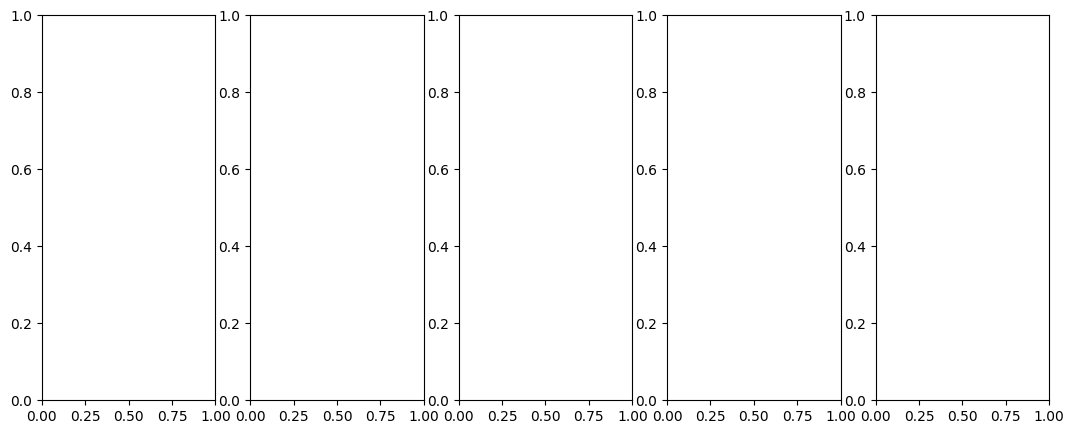

In [11]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow( vgks_recons[j]["x"].reshape((nx,ny)))

plt.show()

# Joint L2 reconstructions?

In [12]:
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
L = build_spatiotemporal_neumann2d(voxel_shape)

In [13]:
v_gks_solver = VanillaGKS(A, L, b_noisy, noise_var=NOISE_VAR)

In [64]:
vdata = v_gks_solver.solve(n_iter=N_ITER, init_dim=5)

3315.7895421901794
4899.681333171954
5115.785616025635
5473.717400103582
6527.642973274755
7681.548401082772
8627.509635656897
9139.338968745837
9264.455759219747
9244.134897155507
9190.860017391271
9173.982932855133
9176.820210564007
9174.08073608189
9162.684969757096
9155.092645301625
9155.727088751886
9162.277715108543
9171.839139432797
9181.22879494675
9188.990420381191
9194.022379416654
9195.555834291921
9193.64345556512
9190.763115208949


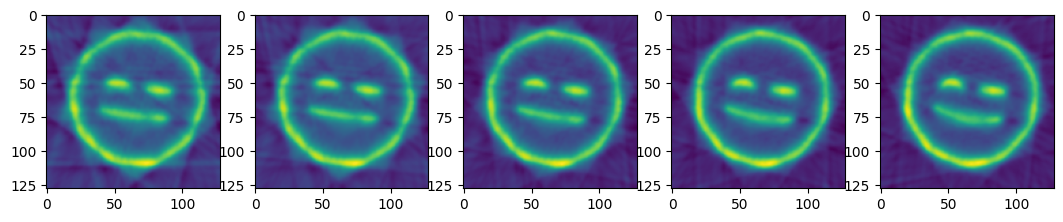

In [65]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# SGKS individualls

In [14]:

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}


In [67]:
sgks_recons = []
for j in range(5):
    A = Aseq[which_times[j]]
    btrunc = B[which_times[j]]
    L = jlinops.Neumann2D((nx, ny))

    mm_gks_solver = MMGKS(A, L, btrunc, noise_var=NOISE_VAR)
    mm_gks_data = mm_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=mm_weight_params)
    sgks_recons.append(mm_gks_data)

204012.09705989418
49.91745257554989
61.43915022170329


66.32294855890136
69.43932247095044
71.27219440506151
72.29672089454968
72.9315096396219
73.27910273138886
73.51370500645977
73.76418285354488
74.04699111944424
74.35898887734629
74.72775617603001
75.07462445647407
75.33351888288699
75.46428804601214
75.5197315628368
75.53792146254102
75.54930620828742
75.55424533303123
75.55759144811549
75.56137715251135
75.57198237999668
75.62032963218384


155005.1345939919
40.99860509974325
50.44520107555974
53.72441928391789
55.98598435432511
57.34918222427821
58.07248217348425
58.57555146507529
58.99454873132037
59.407366155504555
59.81072412286388
60.23160454428558
60.59360875418011
60.86748841781047
61.02742121684749
61.101952799847545
61.14159063388497
61.164121452336005
61.179460503280374
61.19055800363947
61.20065622260627
61.22443911895233
61.29062898264872
61.39956791552754
61.498733804009994


165809.89149529758
41.30962260974218
51.16957581543066
55.03862005185257
57.27120355499211
58.48138307640285
59.17049941884699
59.629599383228346
59.916679430867326
60.16788332475287
60.459996768202686
60.78108796495099
61.08691077678482
61.32914346412957
61.493828000220255
61.59060573207579
61.64385483216907
61.67177249288344
61.6888684809835
61.700025732141036
61.708628137591425
61.719883086933
61.74823620042222
61.8046592490236
61.87521474560167


163617.3840576685
45.356818325416164
56.17475409924771
60.015526247169134
62.51856955687853
64.23210396881446
65.19312157765576
65.7791934098262
66.05868278808846
66.26986475759334
66.50300086836401
66.79755148516038
67.1096750472873
67.43695709027766
67.71532956243011
67.93757421775365
68.07410603130292
68.16755815364769
68.22931333735961
68.26484038708938
68.29123948120595
68.30475113354024
68.3120956306107
68.31587557366201
68.31855924978312


195345.15878472838
48.48440508572606
59.29945853837409
63.34435693454872
66.2192212916097
68.0468512677285
68.92391458555186
69.45444142301685
69.79852726441189
70.09225151572184
70.40277159596833
70.7593832264116
71.16654518990482
71.56817365583338
71.91974973772794
72.12476586080673
72.22073920628105
72.25298484762585
72.2713236222297
72.2829960786796
72.28932604015915
72.29381821574007
72.2990932455988
72.30656588077326
72.32889809978556


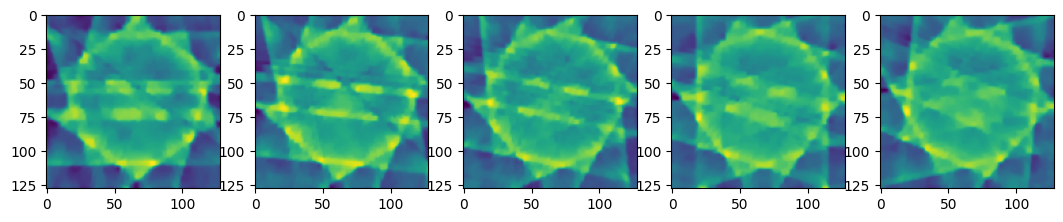

In [68]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow( sgks_recons[j]["x"].reshape((nx,ny)))

plt.show()

# Do S-GKS jointly

In [22]:
A = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in which_times ], voxel_shape)
b = np.hstack([ B[j] for j in which_times ] ) 
L = build_spatiotemporal_neumann2d(voxel_shape)


mm_gks_solver = MMGKS(A, L, b, noise_var=NOISE_VAR)

In [23]:
mm_sgks_data = mm_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=mm_weight_params)

95628.27776568067
21.047726967654235
24.731881591028618
25.953302798311125
26.75447370097427
27.218789259126847
27.613952898532727
28.057274216142456
28.78042896541712
29.357714283424922
29.97082112199009
30.734854938996808
31.315133917273286
31.88144216070149
32.37130743994676
32.799234467992186
33.31682157308079
33.659788417622295
33.840682716124356
33.950035513184496
34.07565853001682
34.16748130071958
34.21663454814462
34.217290780506126
34.220921379300684


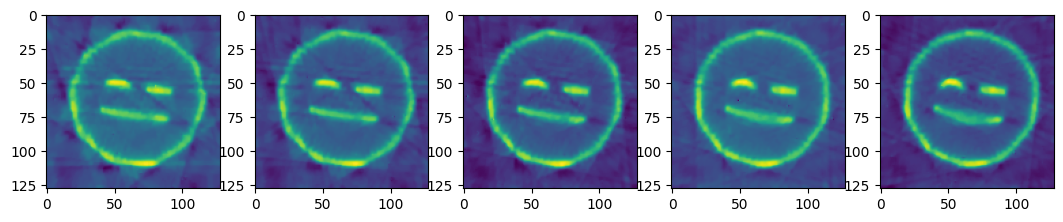

In [24]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

In [25]:
ias_gks_solver = IASGKS(A, L, b, noise_var=NOISE_VAR)

ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}


In [26]:
ias_sgks_data = ias_gks_solver.solve(n_iter=N_ITER, init_dim=5, weight_params=ias_weight_params)

293273.6642097402
9668.779415804225
2705.6766491656726
2258.3357979010652
2469.330932595566
3093.2237849740027
3674.436247923215
4019.3010184783257
4180.407819127368
4233.734111339486
4261.465856047959
4292.461160469126
4322.16040522699
4339.9776395524395
4343.179922387617
4338.004622657956
4335.221276834908
4342.047669077372
4350.836354073488
4355.7378206611265
4355.449687300243
4351.760791986613
4348.137859837635
4347.179549614374
4348.178663469285


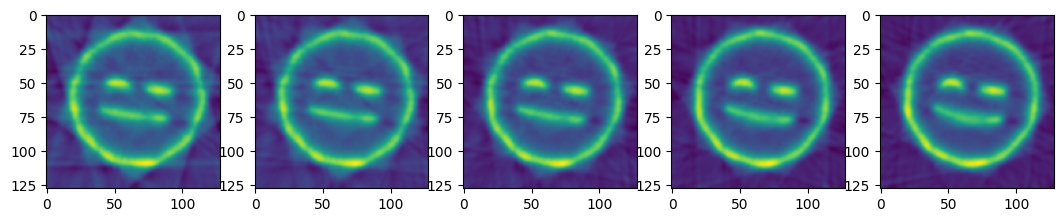

In [27]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(ias_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# PS-GKS?

In [10]:
K = np.ones(A.shape[1])
K = K/np.linalg.norm(K)
K = jlinops.MatrixLinearOperator(K)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedVoxelGradPinvGPUOperator(voxel_shape, weights=w, tol=1e-4, *args, **kwargs)


mm_gks_solver = MMGKS(A, L, b, noise_var=NOISE_VAR, K=K, Lpinv_factory=Lpinv_factory)

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

In [11]:
A.shape

(6510, 49152)

In [12]:
b.shape

(6510,)

In [13]:
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=N_ITER, weight_params=mm_weight_params)

CUDARuntimeError: cudaErrorInitializationError: initialization error

In [13]:
import cupy as cp
# Check memory usage
mempool = cp.get_default_memory_pool()
pinned_mempool = cp.get_default_pinned_memory_pool()

In [16]:
print("Used GPU Memory:", mempool.used_bytes())
#print("Free GPU Memory:", mempool.total_bytes() - mempool.used_bytes())
#print("Pinned Memory Usage:", pinned_mempool.n_bytes)

CUDARuntimeError: cudaErrorInitializationError: initialization error

Exception ignored in: 'cupy.cuda.memory.MemoryPool.used_bytes'
Traceback (most recent call last):
  File "cupy/cuda/device.pyx", line 40, in cupy.cuda.device.get_device_id
  File "cupy_backends/cuda/api/runtime.pyx", line 202, in cupy_backends.cuda.api.runtime.getDevice
  File "cupy_backends/cuda/api/runtime.pyx", line 146, in cupy_backends.cuda.api.runtime.check_status
cupy_backends.cuda.api.runtime.CUDARuntimeError: cudaErrorInitializationError: initialization error


Used GPU Memory: 0


NameError: name 'mm_psgks_data' is not defined

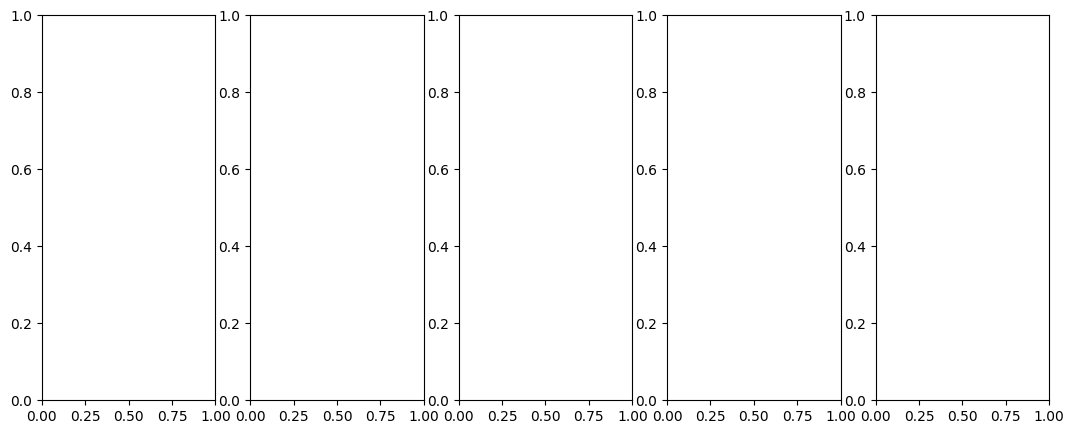

In [20]:
fig, axs = plt.subplots(1,5,figsize=(13,5))

for j in range(5):
    axs[j].imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,j])

plt.show()

# Plot all?

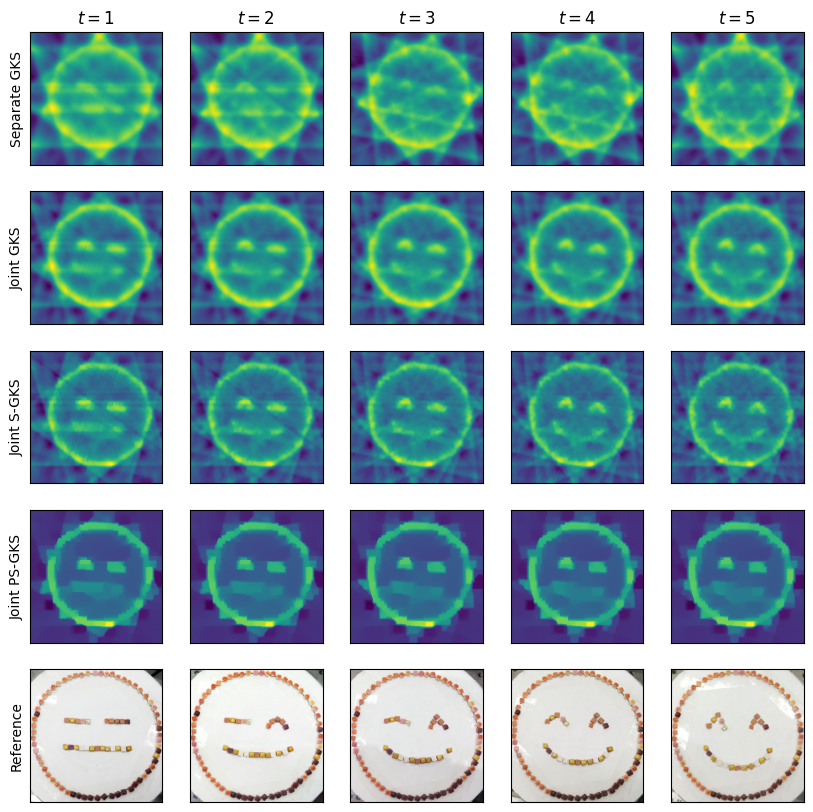

In [30]:
# Rows: individual L2, joint L2, joint S-GKS, joint PS-GKS
fig, axs = plt.subplots(5, 5, figsize=(10,10))

for j in range(5):
    axs[0,j].imshow( vgks_recons[j]["x"].reshape((nx,ny)))
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    axs[0,j].set_title(f"$t = {j+1}$")
axs[0,0].set_ylabel("Separate GKS")


for j in range(5):
    axs[1,j].imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
axs[1,0].set_ylabel("Joint GKS")


for j in range(5):
    axs[2,j].imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
axs[2,0].set_ylabel("Joint S-GKS")


for j in range(5):
    axs[3,j].imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,j])
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
axs[3,0].set_ylabel("Joint PS-GKS")


for j in range(5):
    axs[4,j].imshow(photos[j])
    axs[4,j].set_xticks([])
    axs[4,j].set_yticks([])
axs[4,0].set_ylabel("Reference")



plt.show()